# 07 – Étude de coût : quelle politique de maintenance coûte le moins cher ?

**Question métier :** pour un broyeur, un ventilateur ou un compresseur de cimenterie, vaut-il mieux **attendre la panne**, **remplacer à un âge fixe**, ou **intervenir quand le modèle d'anomalies donne l'alerte** ?

On compare trois politiques (plus une limite théorique) en **dirhams par heure de fonctionnement**, sur des machines **jamais vues** par les modèles :

| Politique | Règle |
|---|---|
| **Corrective** | on répare après la panne |
| **Préventive à âge fixe** | on remplace à l'âge `T*` calculé avec le modèle de survie (Weibull) |
| **Prédictive (anomalies)** | on intervient quand le One-Class SVM déclenche l'alarme (3 mesures consécutives au-dessus du seuil) |
| *Idéale (limite)* | on intervient juste avant chaque panne : personne ne peut faire mieux |

Une alarme déclenche une **intervention préventive** : une fausse alarme coûte donc une préventive inutile, une panne non détectée coûte une corrective.

## Les coûts ci-dessous sont des HYPOTHÈSES ILLUSTRATIVES

In [3]:
import sys, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from lifelines import WeibullFitter
from sklearn.svm import OneClassSVM
from sklearn.preprocessing import StandardScaler

warnings.filterwarnings("ignore")
ROOT = Path(r"D:\master_ai\s1\projet_ml")
sys.path.insert(0, str(ROOT / "src"))
from features import split_by_machine, SENSOR_COLS

(ROOT / "reports/figures").mkdir(parents=True, exist_ok=True)
(ROOT / "reports/tables").mkdir(parents=True, exist_ok=True)
SEED, HEALTHY_H, CONSEC, HOURS_PER_YEAR = 42, 300, 3, 8000

## 1. Hypothèses de coût (en MAD)

Pour chaque type de machine :
- **perte de production par heure d'arrêt** : marge perdue quand la ligne est à l'arrêt,
- **coût de réparation** (pièces + main-d'œuvre) après une panne,
- **coût d'une intervention préventive** (pièces + main-d'œuvre, planifiée).

Les **durées d'arrêt** ne sont pas inventées ici : on les lit dans `maintenance_log.csv` (arrêt moyen après une panne vs après une préventive planifiée).

In [4]:
HYP = pd.DataFrame({
    "perte_prod_par_h":      {"broyeur": 30000, "ventilateur": 20000, "compresseur": 8000},
    "reparation_corrective": {"broyeur": 150000, "ventilateur": 60000, "compresseur": 40000},
    "cout_preventive":       {"broyeur": 20000,  "ventilateur": 8000,  "compresseur": 5000},
}).rename_axis("type")

log = pd.read_csv(ROOT / "data/synthetic/maintenance_log.csv").merge(
    pd.read_csv(ROOT / "data/synthetic/machines.csv"), on="machine_id")
arret = log.groupby(["machine_type", "type"]).downtime_h.mean().unstack()
HYP["arret_panne_h"] = arret["corrective"]
HYP["arret_preventive_h"] = arret["preventive"] if "preventive" in arret else 8.0
HYP["arret_preventive_h"] = HYP["arret_preventive_h"].fillna(8.0)   # pas de préventive dans les données : on prend 8 h

HYP["C_panne"] = HYP.reparation_corrective + HYP.perte_prod_par_h * HYP.arret_panne_h
HYP["C_prev"] = HYP.cout_preventive + HYP.perte_prod_par_h * HYP.arret_preventive_h
HYP["rapport C_panne / C_prev"] = HYP.C_panne / HYP.C_prev
HYP.round(1)

,perte_prod_par_h,reparation_corrective,cout_preventive,arret_panne_h,arret_preventive_h,C_panne,C_prev,rapport C_panne / C_prev
type,,,,,,,,
broyeur,30000,150000,20000,46.1,8.0,1533490.5,260000.0,5.9
ventilateur,20000,60000,8000,45.1,8.0,961740.0,168000.0,5.7
compresseur,8000,40000,5000,46.2,8.0,409857.8,69000.0,5.9


`C_panne` et `C_prev` sont les coûts **totaux** d'une panne et d'une préventive (réparation + production perdue pendant l'arrêt). Le **rapport** entre les deux est ce qui compte : plus une panne coûte cher par rapport à une préventive, plus la prévention est rentable.

## 2. Données et découpage par machine

Même découpage que `04_anomalies` : les modèles sont entraînés sur des machines (`fit`), le seuil d'alarme est choisi sur d'autres (`cal`), et tout est **évalué sur des machines jamais vues** (`test`).

In [5]:
df = pd.read_csv(ROOT / "data/processed/features_temporal.csv")
sv = pd.read_csv(ROOT / "data/synthetic/survival.csv")
sv = sv[sv.duration_h > 0]

train, test = split_by_machine(df, test_size=0.25, seed=SEED)
fit, cal = split_by_machine(train, test_size=0.2, seed=SEED)
cyc = {name: sv[sv.machine_id.isin(d.machine_id.unique())].copy()
       for name, d in [("train", train), ("cal", cal), ("test", test)]}
print({k: f"{len(v)} cycles, {int(v.event.sum())} pannes" for k, v in cyc.items()})

{'train': '169 cycles, 125 pannes', 'cal': '36 cycles, 28 pannes', 'test': '58 cycles, 44 pannes'}


## 3. Scores d'anomalie (One-Class SVM, le meilleur de `04_anomalies`)

In [6]:
FEATURES = [c for c in df.columns if any(c.startswith(s) for s in SENSOR_COLS)]
X_fit = fit.loc[fit.age_h < HEALTHY_H, FEATURES]
scaler = StandardScaler().fit(X_fit)
rng = np.random.default_rng(SEED)
sub = rng.choice(len(X_fit), size=min(5000, len(X_fit)), replace=False)
ocsvm = OneClassSVM(nu=0.05, gamma="scale").fit(scaler.transform(X_fit)[sub])

for d in (cal, test):
    d["score"] = -ocsvm.score_samples(scaler.transform(d[FEATURES]))
print("scores calculés")

scores calculés


## 4. Outils de simulation

Chaque politique est évaluée sur les **cycles de vie historiques** des machines de test : pour un cycle qui a duré `d` heures, on regarde ce que la politique aurait fait.

`coût par heure = somme des coûts / somme des heures de fonctionnement` (méthode renouvellement-récompense : un remplacement ouvre un nouveau cycle indépendant).

In [7]:
def weibull_t_star(w, Cp, Cc, grid=np.arange(10, 8000, 10)):
    """Âge de remplacement qui minimise le coût/h pour une Weibull w."""
    S = np.exp(-(grid / w.lambda_) ** w.rho_)
    rate = (Cp * S + Cc * (1 - S)) / (np.cumsum(S) * 10)
    return grid[np.argmin(rate)]

def first_alarm_age(d, thr):
    """Âge de la première alarme par cycle (alarme = CONSEC mesures consécutives > seuil)."""
    d = d.sort_values(["machine_id", "cycle_id", "time_h"])
    above = (d.score > thr).astype(int)
    alarm = above.groupby([d.machine_id, d.cycle_id]).transform(
        lambda s: s.rolling(CONSEC).min()).fillna(0).astype(bool)
    return d[alarm].groupby(["machine_id", "cycle_id"]).age_h.min().rename("alarm_age")

def evaluate(cycles, C, policy, T_star=None, alarm_age=None):
    """Retourne (coût total, heures) d'une politique sur un tableau de cycles."""
    c = cycles.join(C, on="machine_type")
    d, ev = c.duration_h.values, c.event.values.astype(bool)
    if policy == "corrective":
        stop, t_stop = np.zeros(len(c), bool), d
    elif policy == "ideale":
        cost = np.where(ev, c.C_prev, 0.0)
        return cost.sum(), d.sum()
    elif policy == "fixe":
        T = c.machine_type.map(T_star).values
        stop, t_stop = d > T, np.minimum(d, T)
    elif policy == "alarme":
        a = c.join(alarm_age, on=["machine_id", "cycle_id"]).alarm_age.values
        stop = ~np.isnan(a) & (a < d)
        t_stop = np.where(stop, a, d)
    cost = np.where(stop, c.C_prev, np.where(ev, c.C_panne, 0.0))
    return cost.sum(), t_stop.sum()

def rate(cycles, C, **kw):
    cost, hours = evaluate(cycles, C, **kw)
    return cost / hours        # MAD par heure de fonctionnement

## 5. Choix du seuil d'alarme **par le coût**

Au lieu de fixer le seuil sur un critère statistique, on teste plusieurs seuils (percentiles des scores sains) et on garde celui qui **minimise le coût sur les machines de calibration**. Seuil bas = beaucoup d'alarmes (fausses alarmes coûteuses) ; seuil haut = on rate des pannes.

In [8]:
C = HYP[["C_panne", "C_prev"]]
healthy_cal = cal.loc[cal.age_h < HEALTHY_H, "score"]
QS = [0.90, 0.95, 0.98, 0.99, 0.995, 0.999]   # on s'arrête à 0,999 : au-delà, le percentile repose sur 1 ou 2 mesures seulement

rows = []
for q in QS:
    thr = healthy_cal.quantile(q)
    r_cal = rate(cyc["cal"], C, policy="alarme", alarm_age=first_alarm_age(cal, thr))
    r_test = rate(cyc["test"], C, policy="alarme", alarm_age=first_alarm_age(test, thr))
    rows.append({"percentile du seuil": q, "seuil": thr, "coût/h calibration": r_cal, "coût/h test": r_test})
sweep = pd.DataFrame(rows).set_index("percentile du seuil")
q_star = sweep["coût/h calibration"].idxmin()
thr_star = sweep.loc[q_star, "seuil"]
print(f"Seuil choisi sur la calibration : percentile {q_star}  (score > {thr_star:.2f})")
sweep.round(2)

Seuil choisi sur la calibration : percentile 0.999  (score > -0.09)


,seuil,coût/h calibration,coût/h test
percentile du seuil,,,
0.900,-8.15,297.66,426.00
0.950,-6.63,175.30,259.68
0.980,-4.01,121.09,152.00
0.990,-1.80,101.57,123.82
0.995,-1.25,93.92,112.01
0.999,-0.09,73.52,106.28


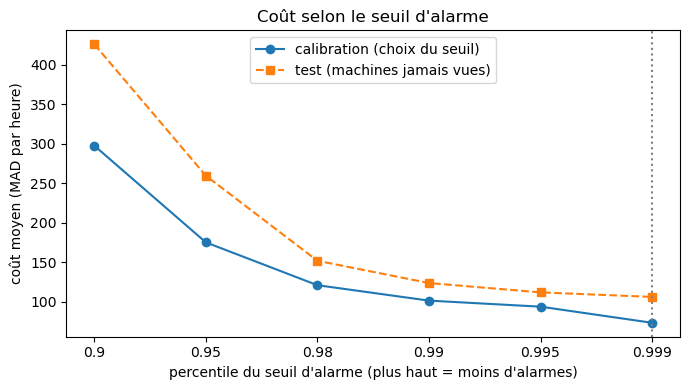

In [9]:
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(sweep.index.astype(str), sweep["coût/h calibration"], "o-", label="calibration (choix du seuil)")
ax.plot(sweep.index.astype(str), sweep["coût/h test"], "s--", label="test (machines jamais vues)")
ax.axvline(str(q_star), color="gray", ls=":")
ax.set_xlabel("percentile du seuil d'alarme (plus haut = moins d'alarmes)")
ax.set_ylabel("coût moyen (MAD par heure)"); ax.set_title("Coût selon le seuil d'alarme"); ax.legend()
plt.tight_layout(); plt.savefig(ROOT / "reports/figures/cout_seuil_alarme.png", dpi=150); plt.show()

## 6. Comparaison des politiques (machines de test)

Les âges de remplacement `T*` sont calculés avec une Weibull ajustée **uniquement sur les machines d'entraînement**.

In [10]:
def fit_t_star(C):
    T = {}
    for mtype, g in cyc["train"].groupby("machine_type"):
        w = WeibullFitter().fit(g.duration_h, g.event)
        T[mtype] = weibull_t_star(w, C.loc[mtype, "C_prev"], C.loc[mtype, "C_panne"])
    return T

T_star = fit_t_star(C)
alarm_test = first_alarm_age(test, thr_star)
pol = {
    "Corrective (attendre la panne)": dict(policy="corrective"),
    "Préventive à âge fixe": dict(policy="fixe", T_star=T_star),
    "Prédictive (alarme anomalies)": dict(policy="alarme", alarm_age=alarm_test),
    "Idéale (limite théorique)": dict(policy="ideale"),
}
res = pd.Series({k: rate(cyc["test"], C, **v) for k, v in pol.items()}, name="MAD/h")
out = res.to_frame()
out["MAD/an/machine"] = (res * HOURS_PER_YEAR).round(-3)
out["économie vs corrective"] = (1 - res / res.iloc[0]).map("{:.0%}".format)
print("Âges de remplacement T* (h) :", T_star)
out.round(0)

Âges de remplacement T* (h) : {'broyeur': np.int64(1160), 'compresseur': np.int64(1490), 'ventilateur': np.int64(1450)}


,MAD/h,MAD/an/machine,économie vs corrective
Corrective (attendre la panne),457.0,3657000.0,0%
Préventive à âge fixe,298.0,2383000.0,35%
Prédictive (alarme anomalies),106.0,850000.0,77%
Idéale (limite théorique),78.0,623000.0,83%


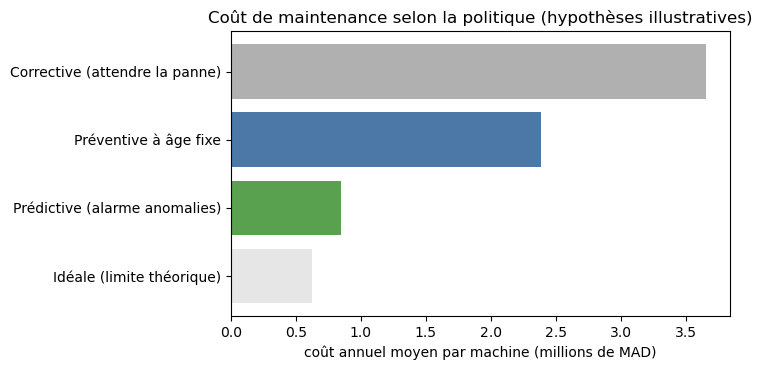

In [11]:
fig, ax = plt.subplots(figsize=(7.5, 3.8))
colors = ["#b0b0b0", "#4c78a8", "#59a14f", "#e6e6e6"]
ax.barh(list(res.index)[::-1], (res * HOURS_PER_YEAR / 1e6).values[::-1], color=colors[::-1])
ax.set_xlabel("coût annuel moyen par machine (millions de MAD)")
ax.set_title("Coût de maintenance selon la politique (hypothèses illustratives)")
plt.tight_layout(); plt.savefig(ROOT / "reports/figures/cout_politiques.png", dpi=150); plt.show()

## 7. Sensibilité : et si nos coûts sont faux ?

Comme les coûts sont des hypothèses, on regarde **comment le classement change** quand la perte de production par heure d'arrêt est multipliée par un facteur. Le seuil d'alarme est re-choisi (sur la calibration) pour chaque facteur.

In [12]:
rows = []
for f in [0.1, 0.25, 0.5, 1, 2, 4]:
    H = HYP.copy()
    H["perte_prod_par_h"] = HYP.perte_prod_par_h * f
    H["C_panne"] = H.reparation_corrective + H.perte_prod_par_h * H.arret_panne_h
    H["C_prev"] = H.cout_preventive + H.perte_prod_par_h * H.arret_preventive_h
    Cf = H[["C_panne", "C_prev"]]
    Tf = fit_t_star(Cf)
    best_q = min(QS, key=lambda q: rate(cyc["cal"], Cf, policy="alarme",
                                        alarm_age=first_alarm_age(cal, healthy_cal.quantile(q))))
    a = first_alarm_age(test, healthy_cal.quantile(best_q))
    rows.append({"facteur perte prod": f,
                 "corrective": rate(cyc["test"], Cf, policy="corrective"),
                 "fixe": rate(cyc["test"], Cf, policy="fixe", T_star=Tf),
                 "alarme": rate(cyc["test"], Cf, policy="alarme", alarm_age=a),
                 "idéale": rate(cyc["test"], Cf, policy="ideale")})
sens = pd.DataFrame(rows).set_index("facteur perte prod")
(sens * HOURS_PER_YEAR / 1e6).round(2)   # millions de MAD par an et par machine

,corrective,fixe,alarme,idéale
facteur perte prod,,,,
0.10,0.67,0.43,0.14,0.10
0.25,1.17,0.78,0.26,0.19
0.50,2.00,1.32,0.46,0.33
1.00,3.66,2.38,0.85,0.62
2.00,6.98,4.53,1.64,1.20
4.00,13.62,8.83,3.21,2.36


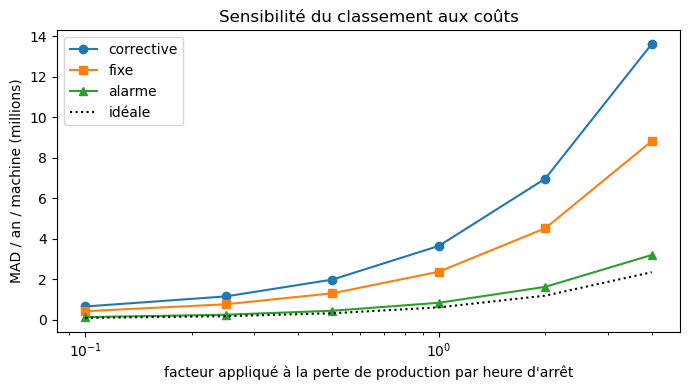

In [13]:
fig, ax = plt.subplots(figsize=(7, 4))
for col, st in [("corrective", "o-"), ("fixe", "s-"), ("alarme", "^-"), ("idéale", "k:")]:
    ax.plot(sens.index, sens[col] * HOURS_PER_YEAR / 1e6, st, label=col)
ax.set_xscale("log"); ax.set_xlabel("facteur appliqué à la perte de production par heure d'arrêt")
ax.set_ylabel("MAD / an / machine (millions)"); ax.legend(); ax.set_title("Sensibilité du classement aux coûts")
plt.tight_layout(); plt.savefig(ROOT / "reports/figures/cout_sensibilite.png", dpi=150); plt.show()

## 8. Sauvegarde

In [14]:
final = out.copy()
final.to_csv(ROOT / "reports/tables/resultats_cout.csv")
sens.round(2).to_csv(ROOT / "reports/tables/resultats_cout_sensibilite.csv")
final

,MAD/h,MAD/an/machine,économie vs corrective
Corrective (attendre la panne),457.099758,3657000.0,0%
Préventive à âge fixe,297.864568,2383000.0,35%
Prédictive (alarme anomalies),106.280236,850000.0,77%
Idéale (limite théorique),77.890082,623000.0,83%
